In [16]:
# here we define a function that we can call to execute our simulation under
# a variety of different alternative scenarios
import numpy as np
import pandas as pd

import shap

%config InlineBackend.figure_format = 'retina'


def run_credit_experiment(
    N,
    job_history_sex_impact=0,
    reported_income_sex_impact=0,
    income_sex_impact=0,
    late_payments_sex_impact=0,
    default_rate_sex_impact=0,
    include_brandx_purchase_score=False,
    include_sex=False,
):
    np.random.seed(0)
    sex = np.random.randint(0, 2, N) == 1  # randomly half men and half women

    # four hypothetical causal factors influence customer quality
    # they are all scaled to the same units between 0-1
    income_stability = np.random.rand(N)
    income_amount = np.random.rand(N)
    if income_sex_impact > 0:
        income_amount -= income_sex_impact / 90000 * sex * np.random.rand(N)
        income_amount -= income_amount.min()
        income_amount /= income_amount.max()
    spending_restraint = np.random.rand(N)
    consistency = np.random.rand(N)

    # intuitively this product says that high customer quality comes from simultaneously
    # being strong in all factors
    customer_quality = income_stability * income_amount * spending_restraint * consistency

    # job history is a random function of the underlying income stability feature
    job_history = np.maximum(
        10 * income_stability + 2 * np.random.rand(N) - job_history_sex_impact * sex * np.random.rand(N),
        0,
    )

    # reported income is a random function of the underlying income amount feature
    reported_income = np.maximum(
        10000
        + 90000 * income_amount
        + np.random.randn(N) * 10000
        - reported_income_sex_impact * sex * np.random.rand(N),
        0,
    )

    # credit inquiries is a random function of the underlying spending restraint and income amount features
    credit_inquiries = np.round(6 * np.maximum(-spending_restraint + income_amount, 0)) + np.round(
        np.random.rand(N) > 0.1
    )

    # credit inquiries is a random function of the underlying consistency and income stability features
    late_payments = np.maximum(
        np.round(3 * np.maximum((1 - consistency) + 0.2 * (1 - income_stability), 0))
        + np.round(np.random.rand(N) > 0.1)
        - np.round(late_payments_sex_impact * sex * np.random.rand(N)),
        0,
    )

    # bundle everything into a data frame and define the labels based on the default rate and customer quality
    X = pd.DataFrame(
        {
            "Job history": job_history,
            "Reported income": reported_income,
            "Credit inquiries": credit_inquiries,
            "Late payments": late_payments,
        }
    )
    default_rate = 0.40 + sex * default_rate_sex_impact
    y = customer_quality < np.percentile(customer_quality, default_rate * 100)

    if include_brandx_purchase_score:
        brandx_purchase_score = sex + 0.8 * np.random.randn(N)
        X["Brand X purchase score"] = brandx_purchase_score

    if include_sex:
        X["Sex"] = sex + 0

    # build model
    import xgboost

    model = xgboost.XGBClassifier(max_depth=1, n_estimators=500, subsample=0.5, learning_rate=0.05, enable_categorical=False)
    model.fit(X, y)

    # build explanation
    import shap

    explainer = shap.TreeExplainer(model, shap.sample(X, 100), feature_perturbation='tree_path_dependent')
    shap_values = explainer.shap_values(X)

    return shap_values, sex, X, explainer.expected_value

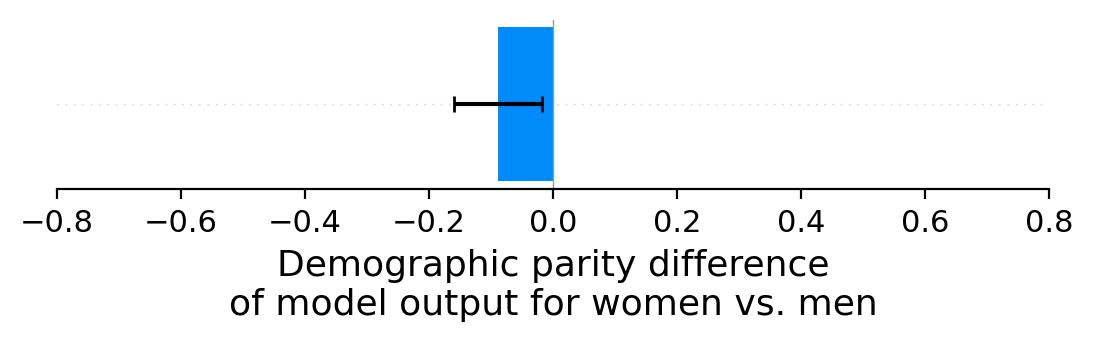

In [30]:
N = 10000
shap_values_A, sex_A, X_A, ev_A = run_credit_experiment(N)
model_outputs_A = ev_A + shap_values_A.sum(1)
glabel = "Demographic parity difference\nof model output for women vs. men"
xmin = -0.8
xmax = 0.8
shap.group_difference_plot(shap_values_A.sum(1), sex_A, xmin=xmin, xmax=xmax, xlabel=glabel)

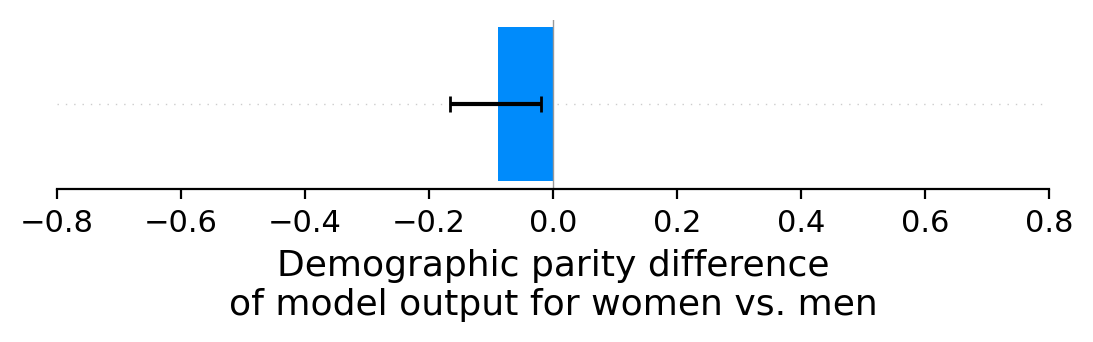

In [32]:
# {차이값} = {여성(True) 그룹의 평균 점수} - {남성(False) 그룹의 평균 점수}
shap.group_difference_plot(
    shap_values_A.sum(1),  # ① 분석 대상 (각 고객의 shap 값 격차 합계)
    sex_A,                 # ② 비교 기준 (성별 그룹: True/False)
    xmin=xmin,             # ③ 그래프 X축의 최소값 (-0.8)
    xmax=xmax,             # ④ 그래프 X축의 최대값 (0.8)
    xlabel=glabel          # ⑤ X축에 표시할 설명 라벨
)

In [26]:
shap_values_A.sum(1)

array([-1.22702839,  1.60335663,  3.04548165, ...,  0.25834227,
       -1.25430193,  5.04229911])

In [19]:
sex_A

array([False,  True,  True, ..., False,  True, False])

In [22]:
X_A.head()

,Job history,Reported income,Credit inquiries,Late payments
0,4.675127,38795.728297,1.0,2.0
1,2.977367,63675.690295,2.0,4.0
2,2.384729,41519.345902,1.0,4.0
3,4.806440,61233.422184,1.0,4.0
4,2.421526,106726.743440,1.0,3.0


In [21]:
ev_A

np.float64(-0.4233687086056848)

In [23]:
model_outputs_A

array([-1.6503971 ,  1.17998792,  2.62211294, ..., -0.16502644,
       -1.67767064,  4.6189304 ])

In [28]:
import numpy as np
import scipy.stats as stats

# 1. 시나리오 A 데이터 준비 (앞선 함수 실행 결과)
# shap_values_A.sum(1)은 모델의 최종 예측 점수(Log-odds)를 나타냅니다.
predictions = shap_values_A.sum(1)

# 2. 성별(sex_A)에 따라 예측 점수 그룹 분할
# sex_A가 True인 그룹(여성)과 False인 그룹(남성)
women_scores = predictions[sex_A == True]
men_scores = predictions[sex_A == False]

# 3. 각 그룹의 기초 통계량 계산
mean_women = np.mean(women_scores)
mean_men = np.mean(men_scores)
diff_mean = mean_women - mean_men

print(f"=== 기초 통계량 ===")
print(f"여성 그룹 샘플 수: {len(women_scores)}명 | 평균 예측 점수: {mean_women:.4f}")
print(f"남성 그룹 샘플 수: {len(men_scores)}명 | 평균 예측 점수: {mean_men:.4f}")
print(f"두 그룹의 평균 차이 (여성 - 남성): {diff_mean:.4f} (그래프의 파란색 막대 길이)\n")

# 4. 독립표본 t-검정 (Independent Two-Sample T-Test) 실행
# 등분산성을 가정하지 않는 Welch's t-test를 기본 적용합니다 (equal_var=False)
t_stat, p_val = stats.ttest_ind(women_scores, men_scores, equal_var=False)

# 5. 95% 신뢰구간(에러 바 범위) 계산
# 두 집단 평균 차이의 표준오차(SE) 계산
se = np.sqrt(np.var(women_scores, ddof=1)/len(women_scores) + np.random.normal(0, 0) + np.var(men_scores, ddof=1)/len(men_scores))
margin_of_error = 1.96 * se
confidence_interval = (diff_mean - margin_of_error, diff_mean + margin_of_error)

print(f"=== t-검정 및 신뢰구간 결과 ===")
print(f"t-통계량 (t-statistic) : {t_stat:.4f}")
print(f"p-값 (p-value)          : {p_val:.4f}")
print(f"95% 신뢰구간 (에러 바)   : [{confidence_interval[0]:.4f} ~ {confidence_interval[1]:.4f}]")

# 6. 통계적 유의성 결론 출력
print("\n=== 최종 결론 ===")
if p_val < 0.05:
    print("👉 p-value가 0.05보다 작으므로, 두 그룹 간의 점수 차이는 통계적으로 '유의미한 차이'가 있습니다.")
    print("   (즉, 오차 범위 내의 잡음이 아니라 실제로 어떤 한쪽 성별에 치우친 예측을 하고 있습니다.)")
else:
    print("👉 p-value가 0.05보다 크므로, 두 그룹 간의 점수 차이는 통계적으로 '유의미하지 않습니다'.")
    print("   (즉, 그래프에서 나타난 차이는 무작위 샘플링에 의한 단순 오차이며 공평한 모델입니다.)")

=== 기초 통계량 ===
여성 그룹 샘플 수: 5085명 | 평균 예측 점수: -0.2226
남성 그룹 샘플 수: 4915명 | 평균 예측 점수: -0.1342
두 그룹의 평균 차이 (여성 - 남성): -0.0884 (그래프의 파란색 막대 길이)

=== t-검정 및 신뢰구간 결과 ===
t-통계량 (t-statistic) : -2.0584
p-값 (p-value)          : 0.0396
95% 신뢰구간 (에러 바)   : [-0.1726 ~ -0.0042]

=== 최종 결론 ===
👉 p-value가 0.05보다 작으므로, 두 그룹 간의 점수 차이는 통계적으로 '유의미한 차이'가 있습니다.
   (즉, 오차 범위 내의 잡음이 아니라 실제로 어떤 한쪽 성별에 치우친 예측을 하고 있습니다.)


### shap 본문에는 차이가 없다고 비지니스적 해석이고 정확한 통계적 해석은 차이가 있다. 예를 들어 N= 1000 명으로 하면?

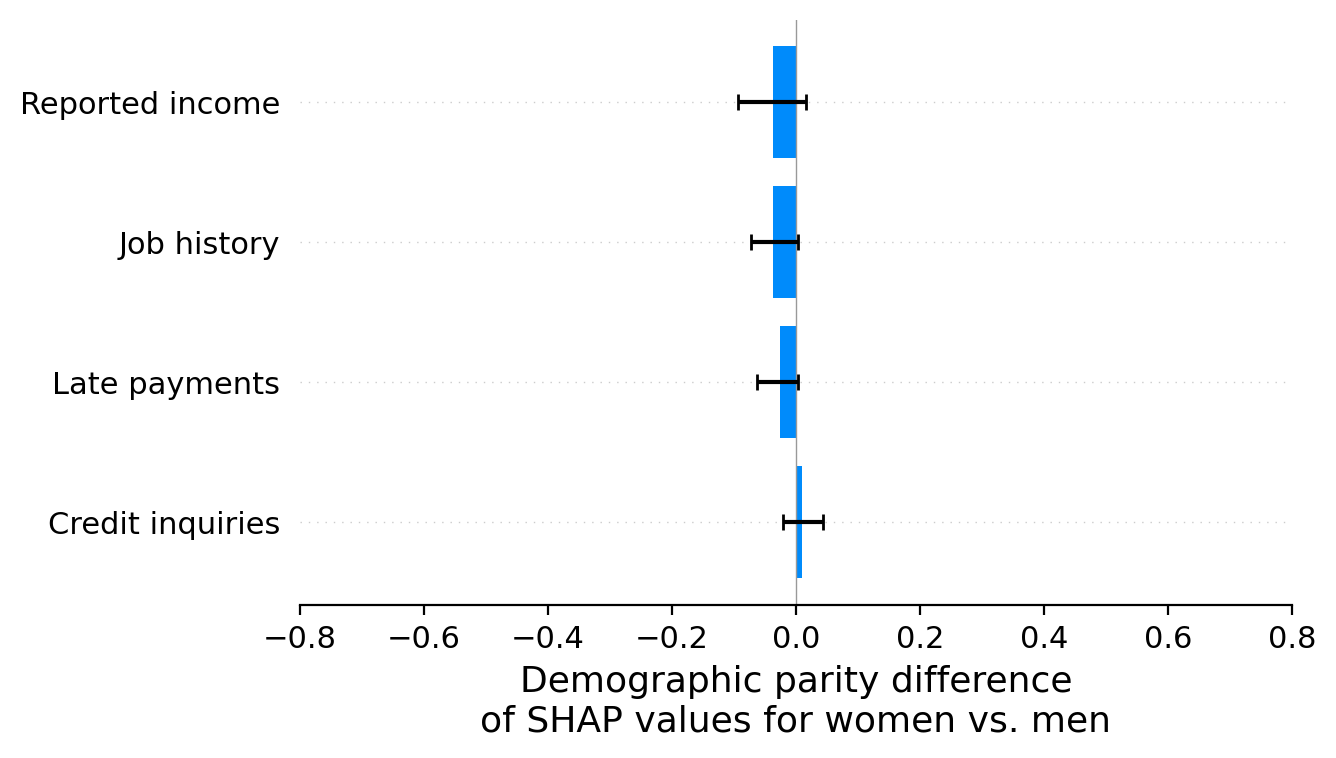

In [31]:
# SHAP의 가장 아름다운 수학적 성질은 "덧셈이 완벽하게 성립한다(Additivity)"는 점
slabel = "Demographic parity difference\nof SHAP values for women vs. men"
shap.group_difference_plot(shap_values_A, sex_A, X_A.columns, xmin=xmin, xmax=xmax, xlabel=slabel)

In [35]:
import numpy as np
import xgboost as xgb
from sklearn.datasets import make_classification

# 1. 테스트용 가상 데이터 생성 (2개 클래스 분류 문제)
X, y = make_classification(n_samples=5, n_features=4, random_state=42)

# 2. XGBoost 모델 학습
model = xgb.XGBClassifier(n_estimators=10, max_depth=3, random_state=42)
model.fit(X, y)

# 3. XGBoost로부터 두 가지 출력값 얻기
# (A) output_margin=True -> 모델 내부의 원시 점수 (Log-odds)
raw_scores = model.predict(X, output_margin=True)

# (B) predict_proba() -> 최종 변환된 예측 확률 (Probability)
# [:, 1]을 사용하여 클래스 1(연체 등)에 속할 확률만 가져옵니다.
probabilities = model.predict_proba(X)[:, 1]

# 4. 수식 검증: 확률(P)을 로그 오즈(Log-odds) 공식으로 직접 역산하기
# 공식: Log-odds = ln(P / (1 - P))
direct_log_odds = np.log(probabilities / (1 - probabilities))

# 5. 결과 비교 출력
import pandas as pd
df_comparison = pd.DataFrame({
    "예측 확률 (Probability)": probabilities,
    "직접 계산한 로그 오즈": direct_log_odds,
    "XGBoost 원시 점수 (Raw Margin)": raw_scores
})

display(df_comparison)

# 두 값이 완벽히 일치하는지 확인 (소수점 오차 감안)
is_identical = np.allclose(direct_log_odds, raw_scores)
print(f"\n👉 두 값은 완벽하게 일치하는가? : {is_identical}")

,예측 확률 (Probability),직접 계산한 로그 오즈,XGBoost 원시 점수 (Raw Margin)
0,0.4,-0.405465,-0.405465
1,0.4,-0.405465,-0.405465
2,0.4,-0.405465,-0.405465
3,0.4,-0.405465,-0.405465
4,0.4,-0.405465,-0.405465



👉 두 값은 완벽하게 일치하는가? : True


In [48]:
from sklearn.datasets import load_breast_cancer
from xgboost import XGBClassifier

X,y = load_breast_cancer(return_X_y=True)

model = XGBClassifier(
    n_estimators=3,
    max_depth=2,
    learning_rate=1,
    eval_metric="logloss",
    random_state=0
)

model.fit(X,y)
prob = model.predict_proba(X[:5])

print(prob)

[[0.91448563 0.08551439]
 [0.9885674  0.0114326 ]
 [0.9885674  0.0114326 ]
 [0.952226   0.04777404]
 [0.91448563 0.08551439]]


In [53]:
margin = model.predict(
    X[:5],
    output_margin=True
)
print(f'Raw Margin(Log Odds) 출력 : {margin}')

prob2 = 1/(1+np.exp(-margin))

print(f'Sigmoid 적용 : {prob2}')

Raw Margin(Log Odds) 출력 : [-2.369677 -4.459788 -4.459788 -2.99232  -2.369677]
Sigmoid 적용 : [0.08551439 0.0114326  0.0114326  0.04777403 0.08551439]


               Training

            ┌─────────────┐
            │   Tree 1                 │
            └──────┬──────┘
                        +0.45
                          │
            ┌──────▼──────┐
            │   Tree 2                 │
            └──────┬──────┘
                        -0.31
                          │
            ┌──────▼──────┐
            │   Tree 3                 │
            └──────┬──────┘
                        +0.76
                          │
                          ▼

             Sum = 0.90  ← Raw Score (Log Odds)
                          │
                          │
                          ▼
             Sigmoid(x)=1/(1+e^-x)
                          │
                          │
                          ▼

                Probability = 0.711

In [55]:
# 첫 번째 데이터
x = X[0:1]

array([[1.799e+01, 1.038e+01, 1.228e+02, 1.001e+03, 1.184e-01, 2.776e-01,
        3.001e-01, 1.471e-01, 2.419e-01, 7.871e-02, 1.095e+00, 9.053e-01,
        8.589e+00, 1.534e+02, 6.399e-03, 4.904e-02, 5.373e-02, 1.587e-02,
        3.003e-02, 6.193e-03, 2.538e+01, 1.733e+01, 1.846e+02, 2.019e+03,
        1.622e-01, 6.656e-01, 7.119e-01, 2.654e-01, 4.601e-01, 1.189e-01]])

In [56]:
margin1 = model.predict(
    x,
    output_margin=True,
    iteration_range=(0,1)
)[0]

print(margin1)

-2.0945835


In [57]:
margin2 = model.predict(
    x,
    output_margin=True,
    iteration_range=(0,2)
)[0]

print(margin2)

-1.239007


In [58]:
margin3 = model.predict(
    x,
    output_margin=True,
    iteration_range=(0,3)
)[0]

print(margin3)

-2.369677


In [59]:
tree1 = margin1
tree2 = margin2 - margin1
tree3 = margin3 - margin2

print(f"Tree1 : {tree1:.6f}")
print(f"Tree2 : {tree2:.6f}")
print(f"Tree3 : {tree3:.6f}")

Tree1 : -2.094584
Tree2 : 0.855577
Tree3 : -1.130670


In [60]:
margin_sum = tree1 + tree2 + tree3

print(margin_sum)
print(margin3)

-2.369677
-2.369677


In [61]:
prob = 1 / (1 + np.exp(-margin_sum))

print(prob)

0.08551439


In [62]:
prob2 = model.predict_proba(x)[0,1]

print("Sigmoid :", prob)
print("predict_proba :", prob2)

Sigmoid : 0.08551439
predict_proba : 0.08551439


### "Tree → Margin → Margin 합 → Sigmoid → Probability"의 과정

In [68]:
X, y = load_breast_cancer(return_X_y=True)

model = XGBClassifier(
    n_estimators=3,
    max_depth=2,
    learning_rate=1,
    eval_metric="logloss",
    random_state=0
)

model.fit(X, y)

x = X[0:1]

# 누적 Margin
m1 = model.predict(x, output_margin=True, iteration_range=(0,1))[0]  # 1번 tree
m2 = model.predict(x, output_margin=True, iteration_range=(0,2))[0]  # 2번 tree
m3 = model.predict(x, output_margin=True, iteration_range=(0,3))[0]  # 3번 tree

# 각 Tree의 기여도
t1 = m1
t2 = m2 - m1
t3 = m3 - m2

print(f"Tree1 Margin : {t1:.6f}")
print(f"Tree2 Margin : {t2:.6f}")
print(f"Tree3 Margin : {t3:.6f}")

margin = t1 + t2 + t3
print(f"\nFinal Margin : {margin:.6f}")
print(f"Final Margin : {m3:.6f}")

prob = 1/(1+np.exp(-margin))

print(f"\nSigmoid Probability : {prob:.6f}")

print(f"predict_proba() : {model.predict_proba(x)[0,1]:.6f}")

Tree1 Margin : -2.094584
Tree2 Margin : 0.855577
Tree3 Margin : -1.130670

Final Margin : -2.369677
Final Margin : -2.369677

Sigmoid Probability : 0.085514
predict_proba() : 0.085514
